# 03 · Model Evaluation — Is My Model Actually Any Good?

A model that's 99% accurate can be worthless, and a model that looks perfect in training can fail on day one in production. This notebook is about **measuring honestly**.

**What you'll learn**
1. Train / validation / test splits, and **data leakage** (the #1 silent bug in ML)
2. **Cross-validation** — 🐍 pure Python → 🔢 NumPy → 📦 scikit-learn
3. **Bias vs variance**: diagnosing under- and overfitting with learning curves
4. Classification metrics: **confusion matrix, precision, recall, F1, ROC-AUC, PR curves** — all built by hand
5. Imbalanced data, and tuning hyperparameters without fooling yourself

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0)

## 1. Why we split the data

Judging a model on the data it trained on is like grading students on exam questions they saw in advance — it measures memory, not understanding. The standard setup:

| Split | Used for | Typical size |
|---|---|---|
| **Training set** | fitting the model's weights | 60–80% |
| **Validation set** | choosing settings (hyperparameters), comparing models | 10–20% |
| **Test set** | one final honest score — touch it **once**, at the end | 10–20% |

If you check the test set after every tweak, you slowly tune to it and its score becomes optimistic. That's why the validation set exists.

In [2]:
# 🐍 Pure Python train/test split
import random

def train_test_split_python(X, y, test_size=0.2, seed=0):
    idx = list(range(len(X)))
    random.Random(seed).shuffle(idx)          # shuffle so the split isn't biased by data order
    n_test = int(len(X) * test_size)
    test_idx, train_idx = idx[:n_test], idx[n_test:]
    return ([X[i] for i in train_idx], [X[i] for i in test_idx],
            [y[i] for i in train_idx], [y[i] for i in test_idx])

Xtr, Xte, ytr, yte = train_test_split_python(list(range(10)), list("abcdefghij"), test_size=0.3)
print("train:", Xtr, " test:", Xte)

train: [5, 3, 4, 2, 0, 9, 6]  test: [7, 8, 1]


**Stratified** splits keep the class proportions the same in each part — essential when one class is rare. **Time-series** data must be split by time (train on the past, test on the future); shuffling would let the model peek at the future.

## 2. Data leakage — the silent killer

Leakage = information from outside the training data sneaks into training, so validation scores look great and real-world performance collapses. Common forms:
- **Preprocessing on the full dataset** (e.g. fitting a scaler or feature selector before splitting).
- **Target leakage:** a feature that's only known *after* the outcome (e.g. "was_refunded" when predicting fraud).
- **Duplicates / same user** appearing in both train and test.
- **Future data** in time-series problems.

Here's a dramatic demonstration: pure **random noise** features, random labels — there is *nothing* to learn. But selecting the "best" features on the full data before cross-validating produces a fake high score:

In [3]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

X_noise = rng.normal(size=(100, 5000))
y_noise = rng.integers(0, 2, 100)

# ❌ WRONG: choose features using ALL the data, then cross-validate
X_sel = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
wrong = cross_val_score(LogisticRegression(max_iter=1000), X_sel, y_noise, cv=5).mean()

# ✅ RIGHT: feature selection inside a pipeline → redone on each training fold only
pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
right = cross_val_score(pipe, X_noise, y_noise, cv=5).mean()

print(f"leaky accuracy on pure noise:  {wrong:.2f}   ← looks like a great model. It's a lie.")
print(f"correct accuracy on pure noise: {right:.2f}   ← coin-flip, the truth")

leaky accuracy on pure noise:  0.85   ← looks like a great model. It's a lie.
correct accuracy on pure noise: 0.48   ← coin-flip, the truth


**Rule:** anything that *learns from data* (scalers, imputers, encoders, feature selectors) must be fit on the training fold only. scikit-learn **Pipelines** enforce this automatically.

## 3. Cross-validation

One validation split is noisy — you might get lucky or unlucky. **k-fold cross-validation** splits the data into k parts ("folds"); each fold takes a turn as the validation set while the other k−1 train. You get k scores: their **mean** estimates performance, their **spread** tells you how much to trust it.

```
fold 1: [VAL][trn][trn][trn][trn]
fold 2: [trn][VAL][trn][trn][trn]
  ...
fold 5: [trn][trn][trn][trn][VAL]
```

In [4]:
# 🐍 Pure Python k-fold
def k_fold_indices_python(n, k=5, seed=0):
    idx = list(range(n))
    random.Random(seed).shuffle(idx)
    fold_size = [n // k + (1 if i < n % k else 0) for i in range(k)]   # spread the remainder
    folds, start = [], 0
    for size in fold_size:
        val = idx[start:start + size]
        train = idx[:start] + idx[start + size:]
        folds.append((train, val))
        start += size
    return folds

for i, (tr, va) in enumerate(k_fold_indices_python(10, k=5)):
    print(f"fold {i}: train={sorted(tr)}  val={sorted(va)}")

fold 0: train=[0, 1, 2, 3, 4, 5, 6, 9]  val=[7, 8]
fold 1: train=[0, 2, 3, 4, 6, 7, 8, 9]  val=[1, 5]
fold 2: train=[0, 1, 2, 5, 6, 7, 8, 9]  val=[3, 4]
fold 3: train=[1, 3, 4, 5, 6, 7, 8, 9]  val=[0, 2]
fold 4: train=[0, 1, 2, 3, 4, 5, 7, 8]  val=[6, 9]


In [5]:
# 🔢 NumPy cross-validation of a model we build ourselves (least-squares linear regression)
from sklearn.datasets import load_diabetes
Xd, yd = load_diabetes(return_X_y=True)

def cross_val_numpy(X, y, k=5, seed=0):
    idx = np.random.default_rng(seed).permutation(len(y))
    scores = []
    for val in np.array_split(idx, k):
        train = np.setdiff1d(idx, val)
        A = np.column_stack([np.ones(len(train)), X[train]])
        theta = np.linalg.lstsq(A, y[train], rcond=None)[0]
        pred = np.column_stack([np.ones(len(val)), X[val]]) @ theta
        scores.append(1 - np.sum((y[val] - pred) ** 2) / np.sum((y[val] - y[val].mean()) ** 2))  # R²
    return np.array(scores)

s = cross_val_numpy(Xd, yd)
print("our CV R² per fold:", s.round(3), f" mean = {s.mean():.3f} ± {s.std():.3f}")

# 📦 scikit-learn: one line
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
s2 = cross_val_score(LinearRegression(), Xd, yd, cv=KFold(5, shuffle=True, random_state=0), scoring="r2")
print("sklearn CV R²:     ", s2.round(3), f" mean = {s2.mean():.3f}")
print("(different random fold assignments, so per-fold numbers differ — but the means agree)")

our CV R² per fold: [0.501 0.503 0.533 0.557 0.343]  mean = 0.487 ± 0.075
sklearn CV R²:      [0.332 0.46  0.537 0.522 0.595]  mean = 0.489
(different random fold assignments, so per-fold numbers differ — but the means agree)


Other CV flavours: **StratifiedKFold** (classification — keeps class ratios), **GroupKFold** (keeps all rows from one user/patient in the same fold), **TimeSeriesSplit** (always validate on later data than you train on).

## 4. Bias vs variance

Every model's error on new data comes from three sources:

$$ \text{Expected error} = \text{Bias}^2 + \text{Variance} + \text{Irreducible noise} $$

- **Bias** — error from wrong assumptions (a line for a curve). Model is *consistently* off. → **Underfitting**.
- **Variance** — error from sensitivity to the particular training sample. Retrain on slightly different data and the model changes a lot. → **Overfitting**.
- **Noise** — randomness in the data itself; no model can remove it.

Making a model more flexible lowers bias but raises variance. The sweet spot is in the middle. Let's *measure* this by training many models on fresh samples:

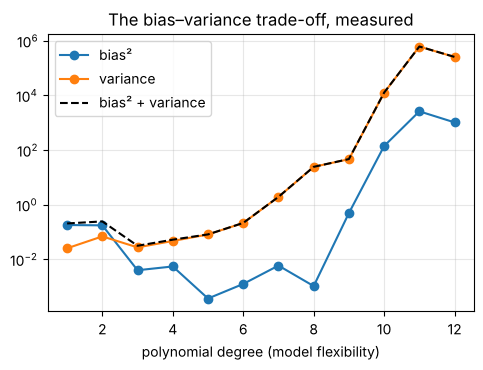

In [6]:
true_f = lambda x: np.sin(2 * x)
x_test = np.linspace(0, 3, 100)
degrees = range(1, 13)
bias2, var = [], []
for deg in degrees:
    preds = []
    for trial in range(200):                                   # 200 different training sets
        xs = rng.uniform(0, 3, 25); ys = true_f(xs) + rng.normal(0, 0.3, 25)
        preds.append(np.polyval(np.polyfit(xs, ys, deg), x_test))
    preds = np.array(preds)
    bias2.append(np.mean((preds.mean(0) - true_f(x_test)) ** 2))
    var.append(np.mean(preds.var(0)))

plt.plot(degrees, bias2, "o-", label="bias²"); plt.plot(degrees, var, "o-", label="variance")
plt.plot(degrees, np.array(bias2) + np.array(var), "k--", label="bias² + variance")
plt.yscale("log"); plt.xlabel("polynomial degree (model flexibility)"); plt.legend()
plt.title("The bias–variance trade-off, measured"); plt.show()

### Diagnosing with learning curves

Plot train and validation scores as the training set grows:
- **High bias:** both curves plateau *low* and close together → more data won't help; use a more powerful model / better features.
- **High variance:** big gap between a high train score and a lower validation score → more data, regularisation, or a simpler model will help.

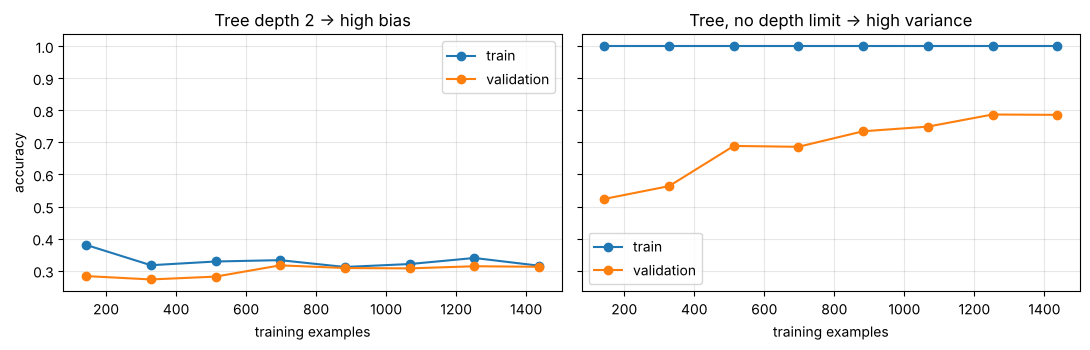

In [7]:
from sklearn.model_selection import learning_curve
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_digits

Xg, yg = load_digits(return_X_y=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, (name, model) in zip(axes, [("Tree depth 2 → high bias", DecisionTreeClassifier(max_depth=2)),
                                     ("Tree, no depth limit → high variance", DecisionTreeClassifier(random_state=0))]):
    sizes, tr, va = learning_curve(model, Xg, yg, cv=5, train_sizes=np.linspace(0.1, 1, 8))
    ax.plot(sizes, tr.mean(1), "o-", label="train"); ax.plot(sizes, va.mean(1), "o-", label="validation")
    ax.set_title(name); ax.set_xlabel("training examples"); ax.legend()
axes[0].set_ylabel("accuracy"); plt.tight_layout(); plt.show()

## 5. Classification metrics

### 5.1 The confusion matrix

Everything starts here. For a binary problem with a "positive" class (e.g. *has disease*):

| | Predicted positive | Predicted negative |
|---|---|---|
| **Actually positive** | **TP** true positive ✅ | **FN** false negative (missed it) ❌ |
| **Actually negative** | **FP** false positive (false alarm) ❌ | **TN** true negative ✅ |

From it:

| Metric | Formula | Question it answers |
|---|---|---|
| **Accuracy** | (TP+TN) / all | How often am I right? (misleading if classes are imbalanced) |
| **Precision** | TP / (TP+FP) | When I say "positive", how often am I right? |
| **Recall** (sensitivity, TPR) | TP / (TP+FN) | Of all real positives, how many did I catch? |
| **Specificity** | TN / (TN+FP) | Of all real negatives, how many did I correctly clear? |
| **F1** | 2·P·R / (P+R) | One number balancing precision & recall (harmonic mean) |

Precision vs recall is a **trade-off** controlled by the threshold: flag more things → higher recall, lower precision.

In [8]:
# 🐍 Pure Python metrics — no magic
def confusion_python(y_true, y_pred):
    tp = sum(1 for t, p in zip(y_true, y_pred) if t == 1 and p == 1)
    tn = sum(1 for t, p in zip(y_true, y_pred) if t == 0 and p == 0)
    fp = sum(1 for t, p in zip(y_true, y_pred) if t == 0 and p == 1)
    fn = sum(1 for t, p in zip(y_true, y_pred) if t == 1 and p == 0)
    return tp, fp, fn, tn

def metrics_python(y_true, y_pred):
    tp, fp, fn, tn = confusion_python(y_true, y_pred)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"accuracy": (tp + tn) / len(y_true), "precision": precision, "recall": recall, "f1": f1}

y_true = [1, 1, 1, 0, 0, 0, 0, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 0, 0, 1, 0]
print("TP, FP, FN, TN =", confusion_python(y_true, y_pred))
print({k: round(v, 3) for k, v in metrics_python(y_true, y_pred).items()})

from sklearn.metrics import precision_score, recall_score, f1_score
print("sklearn:", precision_score(y_true, y_pred), recall_score(y_true, y_pred), round(f1_score(y_true, y_pred), 3))

TP, FP, FN, TN = (3, 1, 1, 5)
{'accuracy': 0.8, 'precision': 0.75, 'recall': 0.75, 'f1': 0.75}
sklearn: 0.75 0.75 0.75


### 5.2 Why accuracy lies on imbalanced data

Fraud detection: 1% of transactions are fraud. A "model" that always says "not fraud" is **99% accurate** and catches zero fraud.

In [9]:
y_imb = (rng.random(10_000) < 0.01).astype(int)
always_no = np.zeros_like(y_imb)
print({k: round(v, 3) for k, v in metrics_python(y_imb.tolist(), always_no.tolist()).items()})

{'accuracy': 0.99, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}


### 5.3 ROC curve and AUC

Instead of picking one threshold, sweep **all** of them. At each, plot:
- **True Positive Rate** (recall) on the y-axis
- **False Positive Rate** = FP / (FP+TN) on the x-axis

A random model is the diagonal; a perfect one hugs the top-left corner. **AUC** (area under the curve) summarises it in one number: **the probability that a random positive gets a higher score than a random negative.** 0.5 = random, 1.0 = perfect.

logistic regression  AUC trapezoid=0.9917  rank=0.9917  sklearn=0.9917
tree (depth 2)       AUC trapezoid=0.8754  rank=0.8754  sklearn=0.8754


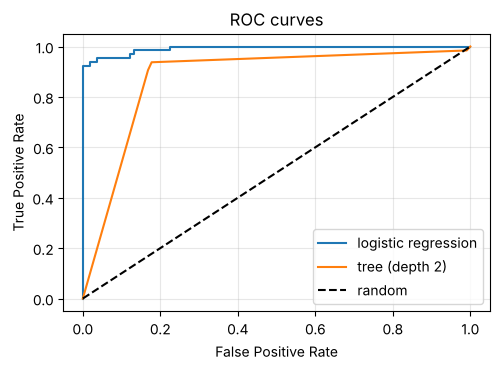

In [10]:
# 🐍 ROC curve + AUC from scratch
def roc_curve_python(y_true, scores):
    pairs = sorted(zip(scores, y_true), reverse=True)        # highest score first
    P = sum(y_true); N = len(y_true) - P
    tpr, fpr, tp, fp = [0.0], [0.0], 0, 0
    for i, (score, label) in enumerate(pairs):               # lower the threshold one example at a time
        if label == 1: tp += 1
        else: fp += 1
        # only record a point once all examples with this exact score are counted —
        # tied scores share one threshold (trees produce many ties!)
        if i == len(pairs) - 1 or pairs[i + 1][0] != score:
            tpr.append(tp / P); fpr.append(fp / N)
    return fpr, tpr

def auc_trapezoid(fpr, tpr):
    return sum((fpr[i] - fpr[i - 1]) * (tpr[i] + tpr[i - 1]) / 2 for i in range(1, len(fpr)))

# The "probability a positive outranks a negative" definition, directly (O(P·N), fine for small data)
def auc_rank_python(y_true, scores):
    pos = [s for s, y in zip(scores, y_true) if y == 1]
    neg = [s for s, y in zip(scores, y_true) if y == 0]
    wins = sum(1.0 if p > n else 0.5 if p == n else 0.0 for p in pos for n in neg)
    return wins / (len(pos) * len(neg))

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

Xc, yc = load_breast_cancer(return_X_y=True)
yc = 1 - yc                                   # make 1 = malignant (the class we want to detect)
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.3, random_state=0, stratify=yc)
models = {"logistic regression": make_pipeline(StandardScaler(), LogisticRegression()),
          "tree (depth 2)": DecisionTreeClassifier(max_depth=2, random_state=0)}
for name, m in models.items():
    scores = m.fit(Xtr, ytr).predict_proba(Xte)[:, 1]
    fpr, tpr = roc_curve_python(yte.tolist(), scores.tolist())
    print(f"{name:20s} AUC trapezoid={auc_trapezoid(fpr, tpr):.4f}  rank={auc_rank_python(yte, scores):.4f}  sklearn={roc_auc_score(yte, scores):.4f}")
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--", label="random"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(); plt.title("ROC curves"); plt.show()

### 5.4 Precision–recall curve (better for rare positives)

When positives are rare, FPR stays tiny even with many false alarms (because TN is huge), so ROC looks flattering. The **PR curve** plots precision vs recall and exposes that. Its summary is **Average Precision (AP)**; a random model scores ≈ the positive rate, not 0.5.

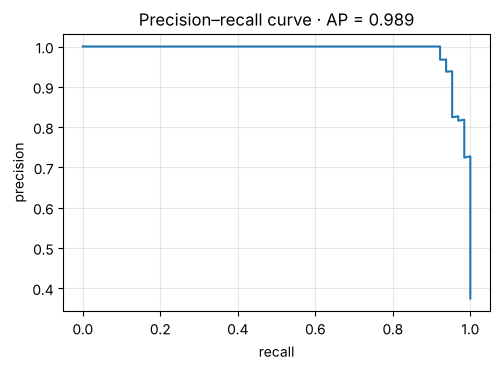

threshold 0.101 → recall 0.984, precision 0.818


In [11]:
from sklearn.metrics import precision_recall_curve, average_precision_score
scores = models["logistic regression"].predict_proba(Xte)[:, 1]
prec, rec, thr = precision_recall_curve(yte, scores)
plt.plot(rec, prec); plt.xlabel("recall"); plt.ylabel("precision")
plt.title(f"Precision–recall curve · AP = {average_precision_score(yte, scores):.3f}"); plt.show()

# Choosing a threshold for a business rule: "catch ≥ 98% of malignant tumours"
i = np.where(rec[:-1] >= 0.98)[0][-1]
print(f"threshold {thr[i]:.3f} → recall {rec[i]:.3f}, precision {prec[i]:.3f}")

## 6. Handling imbalanced data
1. **Use the right metric:** precision/recall/F1, PR-AUC — not accuracy.
2. **Class weights:** make mistakes on the rare class cost more (`class_weight="balanced"`).
3. **Resampling:** oversample the minority (or SMOTE — synthetic examples) / undersample the majority. **Only on the training fold!**
4. **Move the threshold** instead of retraining.

In [12]:
from sklearn.datasets import make_classification
Xi, yi = make_classification(5000, n_features=10, weights=[0.97], flip_y=0.01, random_state=1)
Xtr_i, Xte_i, ytr_i, yte_i = train_test_split(Xi, yi, stratify=yi, random_state=0)
for cw in [None, "balanced"]:
    p = LogisticRegression(class_weight=cw, max_iter=1000).fit(Xtr_i, ytr_i).predict(Xte_i)
    r = metrics_python(yte_i.tolist(), p.tolist())
    print(f"class_weight={str(cw):9s} acc={r['accuracy']:.3f} precision={r['precision']:.3f} recall={r['recall']:.3f} f1={r['f1']:.3f}")

class_weight=None      acc=0.967 precision=0.625 recall=0.116 f1=0.196
class_weight=balanced  acc=0.831 precision=0.132 recall=0.698 f1=0.221


## 7. Tuning hyperparameters without cheating

**Parameters** are learned (weights). **Hyperparameters** are chosen by you (tree depth, regularisation strength, k in KNN). Choose them by cross-validation on the *training* data, then report the test score once.

- **Grid search:** try every combination. Simple, but explodes with many hyperparameters.
- **Random search:** sample combinations randomly — usually finds good settings faster.
- **Bayesian optimisation** (Optuna, etc.): uses past results to pick promising next settings.

In [13]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(DecisionTreeClassifier(random_state=0),
                    {"max_depth": [2, 3, 4, 6, 8, None], "min_samples_leaf": [1, 5, 10]},
                    cv=5, scoring="roc_auc").fit(Xtr, ytr)
print("best settings:", grid.best_params_, f" CV AUC = {grid.best_score_:.4f}")
print(f"final test AUC (looked at once): {roc_auc_score(yte, grid.predict_proba(Xte)[:, 1]):.4f}")

best settings: {'max_depth': 4, 'min_samples_leaf': 10}  CV AUC = 0.9642
final test AUC (looked at once): 0.9597


## 8. Regression metrics — quick reference
| Metric | Use when |
|---|---|
| **RMSE** | big errors are especially bad; same units as y |
| **MAE** | you want robustness to outliers; "average miss" |
| **R²** | comparing to the "predict the mean" baseline |
| **MAPE** | relative error matters (but breaks near y = 0) |

## 9. Key takeaways
- Split before anything else; preprocess **inside** the training fold (use Pipelines).
- Cross-validation gives a mean *and* a spread — report both.
- Big train/val gap → variance (overfit). Both low → bias (underfit).
- Accuracy is misleading on imbalanced data; prefer precision/recall/F1 and PR-AUC.
- The threshold is a separate decision from the model.

## 10. Exercises
1. Using `metrics_python`, compute precision/recall for the breast-cancer logistic model at thresholds 0.1, 0.3, 0.5, 0.7, 0.9. Plot both against the threshold.
2. Repeat the leakage demo but with a `StandardScaler` instead of feature selection. Is the leak still big? Why is scaling leakage usually milder than selection leakage?
3. Implement **stratified** k-fold in pure Python (hint: shuffle each class separately and deal its indices round-robin into folds).

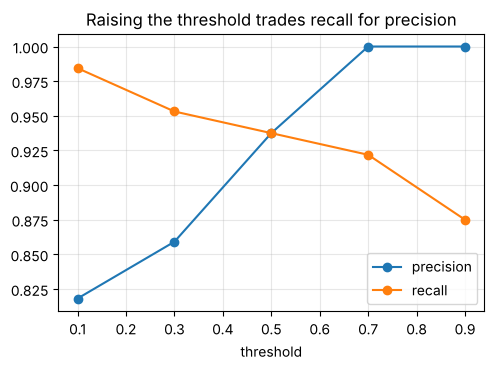

In [14]:
# Exercise 1 — solution
ths = [0.1, 0.3, 0.5, 0.7, 0.9]
res = [metrics_python(yte.tolist(), (scores >= t).astype(int).tolist()) for t in ths]
plt.plot(ths, [r["precision"] for r in res], "o-", label="precision")
plt.plot(ths, [r["recall"] for r in res], "o-", label="recall")
plt.xlabel("threshold"); plt.legend(); plt.title("Raising the threshold trades recall for precision"); plt.show()

In [15]:
# Exercise 3 — solution
def stratified_k_fold_python(y, k=5, seed=0):
    folds = [[] for _ in range(k)]
    for cls in sorted(set(y)):
        idx = [i for i, v in enumerate(y) if v == cls]
        random.Random(seed).shuffle(idx)
        for j, i in enumerate(idx):
            folds[j % k].append(i)
    return [([i for f in folds[:m] + folds[m + 1:] for i in f], folds[m]) for m in range(k)]

for tr, va in stratified_k_fold_python(yc.tolist(), k=5):
    print(f"val size {len(va)}, positive rate {np.mean(yc[va]):.3f}  (overall {yc.mean():.3f})")

val size 115, positive rate 0.374  (overall 0.373)
val size 115, positive rate 0.374  (overall 0.373)
val size 113, positive rate 0.372  (overall 0.373)
val size 113, positive rate 0.372  (overall 0.373)
val size 113, positive rate 0.372  (overall 0.373)


**Next:** [04 · KNN, Naive Bayes & SVM](04_knn_naive_bayes_svm.ipynb) — three very different ways to classify.

*Going deeper / interview prep:* `ML_Interview_Notes.md` §2.1 (bias-variance derivation), §2.3 (validation & leakage), §2.4 (metrics), §2.5 (imbalance) · `ML_System_Design_Notes.md` §2.2 (label leakage) · `Probability_Statistics_Notes.md` §3.4 (bootstrap) · code: `ml_from_scratch.py` sections 1–2.